#En este paso relice la instalacion e importacion de libreiras

In [2]:
import numpy as np
import pandas as pd

#se define "df" como variable para realizar la carga de la base de dato

In [3]:
df =  pd.read_csv("base_datos_restaurantes_usa_v2.csv")


#Se realizo la primera inspeccion de la base de datos con el metodo .head de pandas

In [4]:
df.head()

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,Jackson,Gomez,31.0,Masculino,Miami,Alto,6,67.51,Sí,No,Vegetariano,Sí,(830)220-1926,NaN,Efectivo,6425
1,9446112038,Samantha,Soto,40.0,Femenino,Denver,Medio,2,44.92,Sí,Sí,Mariscos,No,881-476-1426,NaN,Efectivo,2374
2,3098363243,Terry,Adams,62.0,Femenino,Denver,Bajo,2,9.24,Sí,Sí,Vegetariano,No,NaN,diana74@example.net,Efectivo,1110
3,4013002847,James,Shannon,41.0,Masculino,Boston,Alto,5,30.74,Sí,Sí,Carnes,Sí,NaN,scottfrey@example.com,Tarjeta,6931
4,7372911048,Susan,Jones,49.0,Femenino,San Diego,Bajo,0,0.00,No,No,Carnes,No,243.248.8919,glassgary@example.org,Tarjeta,1350


#Se selecciono la ciudad Boston para el analisis correspondiente de los datos especificos de esta ciudad

In [5]:
df_Boston=df[df["ciudad_residencia"] == "Boston"]

#Se utilizo el atributo .shape para saber cuantas filas y columnas correspondia a Boston

In [6]:
df_Boston.shape

(2547, 17)

#aca se hizo identificacion de cantidad de nulos existente por columna

In [7]:
df_Boston.isnull().sum()

id_persona                      0
nombre                          0
apellido                        0
edad                           10
genero                          0
ciudad_residencia               0
estrato_socioeconomico          0
frecuencia_visita               0
promedio_gasto_comida           6
ocio                            0
consume_licor                   0
preferencias_alimenticias     102
membresia_premium               0
telefono_contacto            1264
correo_electronico           1276
tipo_de_pago_mas_usado          0
ingresos_mensuales              0
dtype: int64

#Se utilizo estos dos metodos para sumar los duplicados

In [8]:
df_Boston.duplicated().sum()

np.int64(0)

#Resume los datos de las columnas donde podemos identificar lo vacio o faltnates

In [9]:
df_Boston.info()

<class 'pandas.DataFrame'>
Index: 2547 entries, 3 to 29976
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_persona                 2547 non-null   int64  
 1   nombre                     2547 non-null   str    
 2   apellido                   2547 non-null   str    
 3   edad                       2537 non-null   float64
 4   genero                     2547 non-null   str    
 5   ciudad_residencia          2547 non-null   str    
 6   estrato_socioeconomico     2547 non-null   str    
 7   frecuencia_visita          2547 non-null   int64  
 8   promedio_gasto_comida      2541 non-null   float64
 9   ocio                       2547 non-null   str    
 10  consume_licor              2547 non-null   str    
 11  preferencias_alimenticias  2445 non-null   str    
 12  membresia_premium          2547 non-null   str    
 13  telefono_contacto          1283 non-null   str    
 14  correo_

#Con esta funcion se puede detectar aquellas inconsistencias como se aprecia en edad y frecuencia donde los valores son negativos y no corresponden al tipo de dato que deberia estar establecido 

In [10]:
df_Boston.describe()

,id_persona,edad,frecuencia_visita,promedio_gasto_comida,ingresos_mensuales
count,2.547000e+03,2537.000000,2547.000000,2541.000000,2547.000000
mean,5.548750e+09,49.512810,3.980762,29.494766,5658.080487
std,2.620686e+09,23.670266,2.792514,23.960740,4725.407151
min,1.010508e+09,-5.000000,-3.000000,0.000000,807.000000
25%,3.234152e+09,33.000000,2.000000,11.340000,1852.500000
50%,5.642463e+09,49.000000,4.000000,22.790000,3657.000000
75%,7.760216e+09,65.000000,6.000000,41.170000,8237.000000
max,9.993177e+09,300.000000,10.000000,104.600000,17972.000000


#ya identificado los valores inconsistentes, se usa un filtro condicional para identifica con mas precision, los registro cuya edad es menor que cero

In [11]:
df_Boston[df_Boston["edad"] < 0]

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
2482,1737293582,Holly,Gallagher,-5.0,Femenino,Boston,Medio,4,22.82,Sí,No,Carnes,No,NaN,websteramanda@example.org,Efectivo,2836
6777,6826129434,Megan,Russell,-5.0,Femenino,Boston,Medio,3,7.20,No,Sí,Pescado,No,NaN,walkerwilliam@example.net,App,2330
14448,9852786935,Crystal,Jenkins,-5.0,Femenino,Boston,Muy Alto,10,69.67,No,Sí,Carnes,Sí,345.625.4596,NaN,Efectivo,12586
24330,3334126899,Beth,Nicholson,-5.0,Femenino,Boston,Alto,4,19.51,Sí,Sí,Vegetariano,Sí,3149433778,NaN,Efectivo,7730
26734,9433104084,Albert,Johnson,-5.0,Masculino,Boston,Alto,-3,11.55,No,No,Mariscos,Sí,NaN,NaN,Efectivo,4451


#de igual forma se realizo el filtrado de edad con esta condicional de mayor a 100 años

In [12]:
df_Boston[(df_Boston["edad"] > 100)]

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
2101,4640435053,Adam,Young,300.0,Masculino,Boston,Medio,4,14.13,No,Sí,Vegetariano,No,NaN,ryan08@example.com,App,2958
2529,6228635509,Jason,Matthews,300.0,Masculino,Boston,Muy Alto,10,85.96,No,No,Mariscos,Sí,(879)385-9416,kathyjones@example.com,Tarjeta,9729
4492,6448324230,Erik,Martinez,300.0,Masculino,Boston,Bajo,3,13.81,No,Sí,Carnes,No,NaN,NaN,Tarjeta,1364
6313,2539612479,Brian,Farrell,300.0,Masculino,Boston,Medio,3,32.56,No,Sí,Carnes,No,370-361-2950x83474,ymolina@example.com,Tarjeta,2892
9661,6934932642,Jonathan,Sims,300.0,Masculino,Boston,Alto,5,5.40,Sí,No,Otro,No,(611)682-4018x8904,jessica55@example.org,Tarjeta,8060
13785,9263135031,Amy,Matthews,300.0,Femenino,Boston,Alto,4,7.58,No,No,Carnes,No,NaN,NaN,App,4382
19943,1546416390,Caleb,Anderson,300.0,Masculino,Boston,Bajo,3,14.57,Sí,Sí,Carnes,No,NaN,NaN,App,1474
24022,3656689261,Anna,Blanchard,300.0,Femenino,Boston,Muy Alto,7,102.93,Sí,Sí,Otro,Sí,NaN,igarza@example.com,Efectivo,10230
28038,2092282503,Bryan,Pratt,300.0,Masculino,Boston,Muy Alto,8,22.44,No,No,Otro,Sí,701-452-1033,lindsay47@example.net,Efectivo,9582


#En este metodo se pudo identificar aquellos datos inconsistentes que tenian numeros negativos

In [13]:
df_Boston[df_Boston["frecuencia_visita"] < 0]

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
496,1420654268,Keith,Hensley,42.0,Masculino,Boston,Muy Alto,-3,104.17,Sí,Sí,Vegano,Sí,NaN,raymondbeasley@example.org,Efectivo,9806
602,9674596936,Lauren,Kelly,19.0,Femenino,Boston,Medio,-3,5.88,Sí,Sí,NaN,No,445.962.1555,eric16@example.net,App,2726
734,9190753627,Danielle,Abbott,27.0,Femenino,Boston,Medio,-3,13.69,No,Sí,Pescado,No,365-598-1157,cbass@example.net,Efectivo,2450
969,9872029928,Sarah,Miller,42.0,Femenino,Boston,Alto,-3,36.58,No,Sí,Vegetariano,No,NaN,kellystone@example.com,App,6940
1051,5853660504,Victor,Gibbs,68.0,Masculino,Boston,Bajo,-3,13.22,Sí,No,Pescado,No,001-586-421-7008x781,davisdaniel@example.org,Efectivo,1265
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29124,3937505620,Sarah,Collins,71.0,Femenino,Boston,Muy Alto,-3,89.25,Sí,No,Carnes,Sí,NaN,NaN,Tarjeta,10280
29247,4540608132,Michelle,Thompson,70.0,Femenino,Boston,Alto,-3,7.45,No,No,Vegetariano,Sí,+1-449-217-8781x98931,matthewthomas@example.org,Tarjeta,5923
29354,8914054579,Ellen,Foster,41.0,Femenino,Boston,Medio,-3,30.28,Sí,No,Carnes,Sí,NaN,NaN,Efectivo,2071
29750,6869865000,Sandra,Cisneros,37.0,Femenino,Boston,Alto,-3,20.93,Sí,No,Carnes,No,NaN,NaN,Tarjeta,6999


In [14]:
df_Boston["frecuencia_visita"].describe()

count    2547.000000
mean        3.980762
std         2.792514
min        -3.000000
25%         2.000000
50%         4.000000
75%         6.000000
max        10.000000
Name: frecuencia_visita, dtype: float64

In [15]:
df_Boston.groupby("preferencias_alimenticias")["frecuencia_visita"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
preferencias_alimenticias,,,
Carnes,535,4.185047,4.0
Mariscos,493,3.890467,4.0
Otro,198,3.984848,4.0
Pescado,272,3.816176,4.0
Vegano,239,4.050209,4.0
Vegetariano,708,3.937853,4.0


#Promediando con esta funcion se puede verificar nuevamente los datos inconsistentes relacionados a esta columna

In [16]:
df_Boston["promedio_gasto_comida"].describe()

count    2541.000000
mean       29.494766
std        23.960740
min         0.000000
25%        11.340000
50%        22.790000
75%        41.170000
max       104.600000
Name: promedio_gasto_comida, dtype: float64

#Se verifica si hay un dato por debajo de 0

In [17]:
(df_Boston["promedio_gasto_comida"] < 0).sum()

np.int64(0)

#Con este metodo se puede ordenar los datos de mayo a menor, incluyendo los vacion de cada columna y identificar las preferencias del cliente

In [18]:
(df_Boston["preferencias_alimenticias"].value_counts(dropna=False))

preferencias_alimenticias
Vegetariano    708
Carnes         535
Mariscos       493
Pescado        272
Vegano         239
Otro           198
NaN            102
Name: count, dtype: int64

#en este punto se identifica la tendencia de consumo de licor

In [19]:
(df_Boston["consume_licor"].value_counts(dropna=False))

consume_licor
Sí    1612
No     935
Name: count, dtype: int64

#col el mismo metodo identificamos la tendencia de genero

In [20]:
(df_Boston["genero"].value_counts(dropna=False))

genero
Femenino     1309
Masculino    1238
Name: count, dtype: int64

#y por ultimo con el metodo se ordena de mayor a menos el estatro socioeconomico de los clientes

In [21]:
(df_Boston["estrato_socioeconomico"].value_counts(dropna=False))

estrato_socioeconomico
Alto        759
Medio       729
Muy Alto    533
Bajo        526
Name: count, dtype: int64

#AVANCE 3

#Se realiza instalacion de librerias y estilo visual para una presentacion uniforme

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

#Se realizó una revisión de las columnas del DataFrame mediante df.columns.tolist(), con el propósito de identificar las variables disponibles

In [23]:
df.columns.tolist()

['id_persona',
 'nombre',
 'apellido',
 'edad',
 'genero',
 'ciudad_residencia',
 'estrato_socioeconomico',
 'frecuencia_visita',
 'promedio_gasto_comida',
 'ocio',
 'consume_licor',
 'preferencias_alimenticias',
 'membresia_premium',
 'telefono_contacto',
 'correo_electronico',
 'tipo_de_pago_mas_usado',
 'ingresos_mensuales']

#Se utilizó value_counts() para contabilizar los clientes según su ciudad de residencia.

In [24]:
personas_por_ciudad = df["ciudad_residencia"].value_counts()

personas_por_ciudad

ciudad_residencia
Chicago      5384
NYC          4769
Miami        3186
San Diego    3075
Dallas       2602
Boston       2547
Denver       2523
Houston      2212
Seattle      2191
Phoenix      1511
Name: count, dtype: int64

#Se construyó un gráfico de barras para representar la cantidad de clientes registrados en cada ciudad, facilitando la comparación de su distribución geográfica.

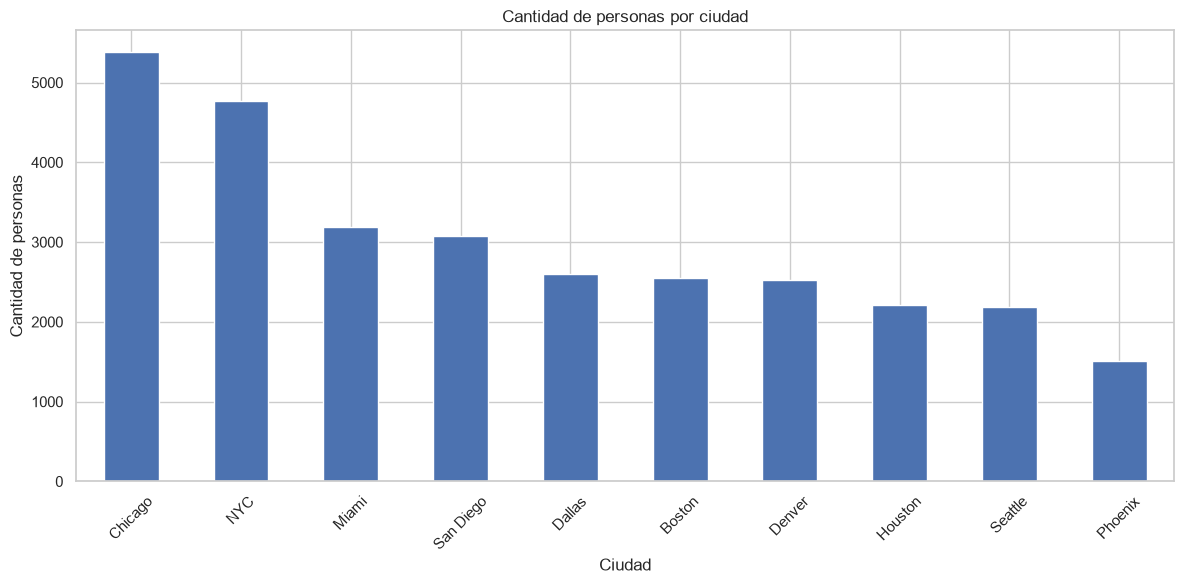

In [25]:
plt.figure(figsize=(12, 6))

personas_por_ciudad.plot(kind="bar")

plt.title("Cantidad de personas por ciudad")
plt.xlabel("Ciudad")
plt.ylabel("Cantidad de personas")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

#Se contabilizaron los clientes según su estrato socioeconómico, incluyendo todas las categorías registradas.

In [26]:
personas_por_estrato = df["estrato_socioeconomico"].value_counts(
    dropna=False
)

personas_por_estrato

estrato_socioeconomico
Medio       9325
Alto        9038
Bajo        6161
Muy Alto    5476
Name: count, dtype: int64

#Se utilizó describe() para obtener las estadísticas descriptivas de la variable promedio_gasto_comida.

In [27]:
df["promedio_gasto_comida"].describe()

count    29855.000000
mean        32.603452
std         26.402601
min          0.000000
25%         13.290000
50%         25.510000
75%         44.400000
max        149.970000
Name: promedio_gasto_comida, dtype: float64

#Se agrupó la información por ciudad y se calculó el gasto promedio y la cantidad de registros disponibles. Los resultados se ordenaron de mayor a menor para identificar las ciudades con mayor gasto promedio.

In [28]:
gasto_por_ciudad = df.groupby("ciudad_residencia")[
    "promedio_gasto_comida"
].agg(["mean", "count"])

gasto_por_ciudad = gasto_por_ciudad.sort_values(
    by="mean",
    ascending=False
)

gasto_por_ciudad

,mean,count
ciudad_residencia,,
Miami,39.821543,3170
NYC,37.123200,4753
Seattle,36.861784,2181
Phoenix,36.544770,1503
San Diego,34.751539,3061
Denver,34.264096,2510
Boston,29.494766,2541
Dallas,28.695238,2587
Houston,26.020559,2200


#Se elaboró un gráfico de barras para comparar el gasto promedio en comida entre las diez ciudades, identificando las diferencias en el comportamiento de gasto de los clientes.

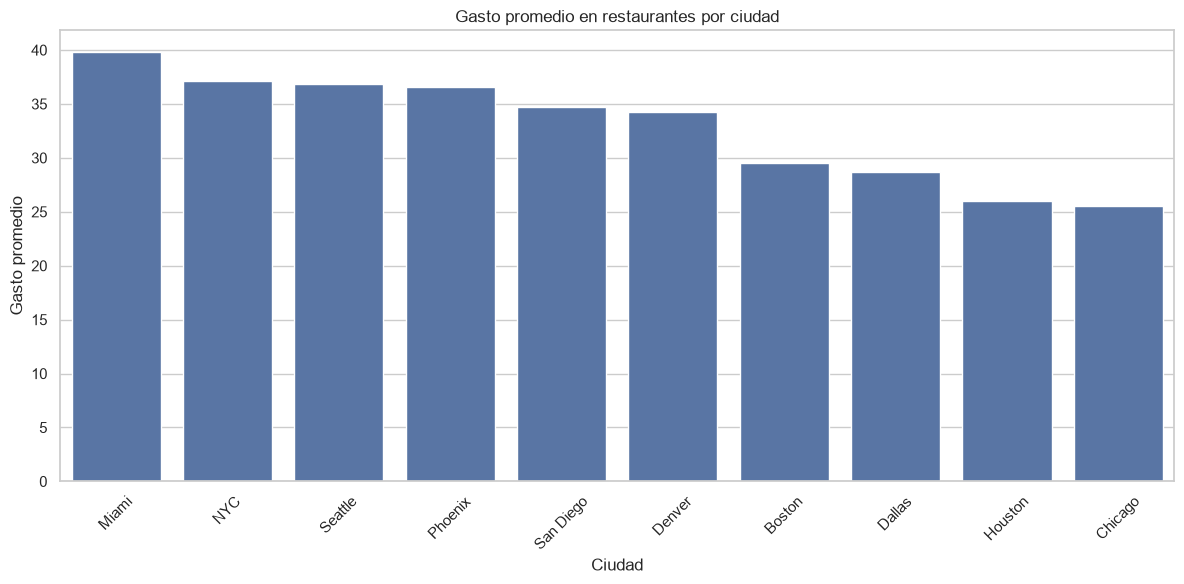

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=gasto_por_ciudad.index,
    y=gasto_por_ciudad["mean"]
)

plt.title("Gasto promedio en restaurantes por ciudad")
plt.xlabel("Ciudad")
plt.ylabel("Gasto promedio")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


#Se utilizó describe(include="all") para examinar las variables de frecuencia de visita, gasto promedio en comida y estrato socioeconómico, identificando sus principales características estadísticas y distribución.

In [30]:
df[[
    "frecuencia_visita",
    "promedio_gasto_comida",
    "estrato_socioeconomico"
]].describe(include="all")

,frecuencia_visita,promedio_gasto_comida,estrato_socioeconomico
count,30000.000000,29855.000000,30000
unique,NaN,NaN,4
top,NaN,NaN,Medio
freq,NaN,NaN,9325
mean,3.896133,32.603452,NaN
std,2.741532,26.402601,NaN
min,-3.000000,0.000000,NaN
25%,2.000000,13.290000,NaN
50%,4.000000,25.510000,NaN
75%,5.000000,44.400000,NaN


#Se identificaron 1.547 registros con valores negativos en la variable frecuencia_visita, con el propósito de evaluar la calidad de los datos antes de realizar el análisis comparativo.

In [31]:
df[df["frecuencia_visita"] < 0].shape

(1547, 17)

#Se creó una copia de la base de datos, conservando registros con frecuencia de visita igual o superior a cero y valores disponibles en promedio_gasto_comida, para evitar inconsistencias en el análisis.

In [32]:
df_analisis = df[
    (df["frecuencia_visita"] >= 0) &
    (df["promedio_gasto_comida"].notna())
].copy()

Después de aplicar los filtros, se conservaron 28.318 registros y 17 variables, que serán utilizados para analizar la relación entre la frecuencia de visita y el gasto promedio según el estrato socioeconómico.

In [33]:
df_analisis.shape

(28318, 17)

#Se agruparon los registros por estrato socioeconómico y se calcularon la frecuencia promedio de visita, el gasto promedio y la cantidad de clientes.

In [34]:
resumen_estrato = df_analisis.groupby(
    "estrato_socioeconomico"
).agg(
    frecuencia_promedio=("frecuencia_visita", "mean"),
    gasto_promedio=("promedio_gasto_comida", "mean"),
    cantidad_personas=("id_persona", "count")
)

resumen_estrato

,frecuencia_promedio,gasto_promedio,cantidad_personas
estrato_socioeconomico,,,
Alto,5.009631,38.182323,8514
Bajo,1.501199,8.729726,5836
Medio,3.497552,24.237644,8781
Muy Alto,7.481589,64.175672,5187


#Se construyó un gráfico de dispersión para comparar la frecuencia promedio de visita y el gasto promedio en comida, diferenciando los resultados por estrato socioeconómico.

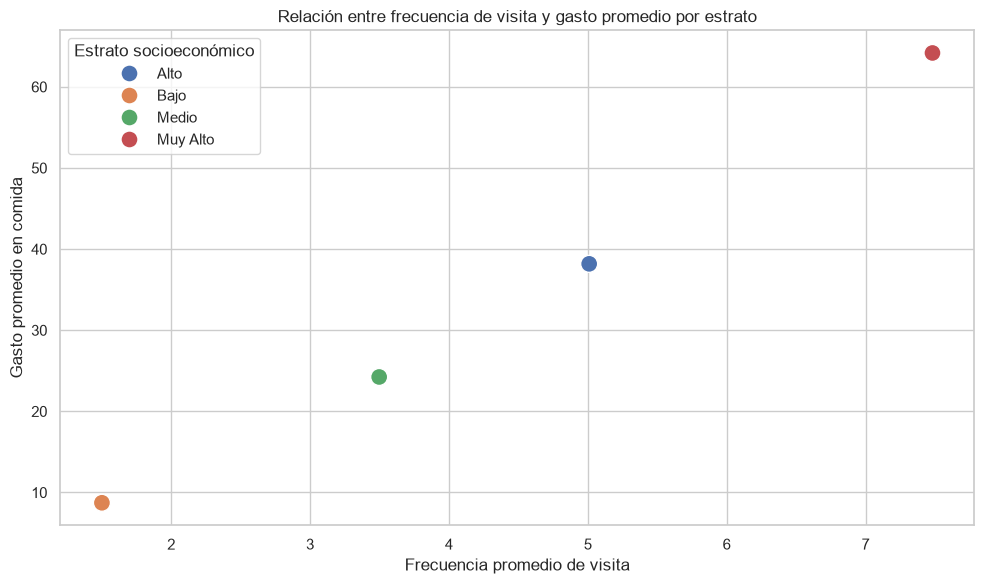

In [35]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=resumen_estrato,
    x="frecuencia_promedio",
    y="gasto_promedio",
    hue=resumen_estrato.index,
    s=150
)

plt.title("Relación entre frecuencia de visita y gasto promedio por estrato")
plt.xlabel("Frecuencia promedio de visita")
plt.ylabel("Gasto promedio en comida")
plt.legend(title="Estrato socioeconómico")
plt.tight_layout()
plt.show()

#Se analizaron los ingresos mensuales y el gasto promedio en comida mediante estadísticas descriptivas, identificando sus valores centrales, dispersión y rangos.

In [36]:
df[[
    "promedio_gasto_comida",
    "ingresos_mensuales"
]].describe()

,promedio_gasto_comida,ingresos_mensuales
count,29855.000000,30000.000000
mean,32.603452,5389.755867
std,26.402601,4538.491728
min,0.000000,800.000000
25%,13.290000,1860.000000
50%,25.510000,3402.000000
75%,44.400000,7761.000000
max,149.970000,17999.000000


#Se creó un DataFrame con las variables promedio_gasto_comida e ingresos_mensuales, eliminando los registros con valores nulos mediante dropna().

In [37]:
df_gasto_ingresos = df[
    ["promedio_gasto_comida", "ingresos_mensuales"]
].dropna().copy()

#se conservaron 29.855 registros y 2 variables para analizar la relación entre ingresos y gastos.

In [38]:
df_gasto_ingresos.shape

(29855, 2)

#Se elaboró un gráfico de dispersión para observar la relación entre los ingresos mensuales y el gasto promedio en comida de los clientes, identificando posibles patrones de comportamiento entre ambas variables.

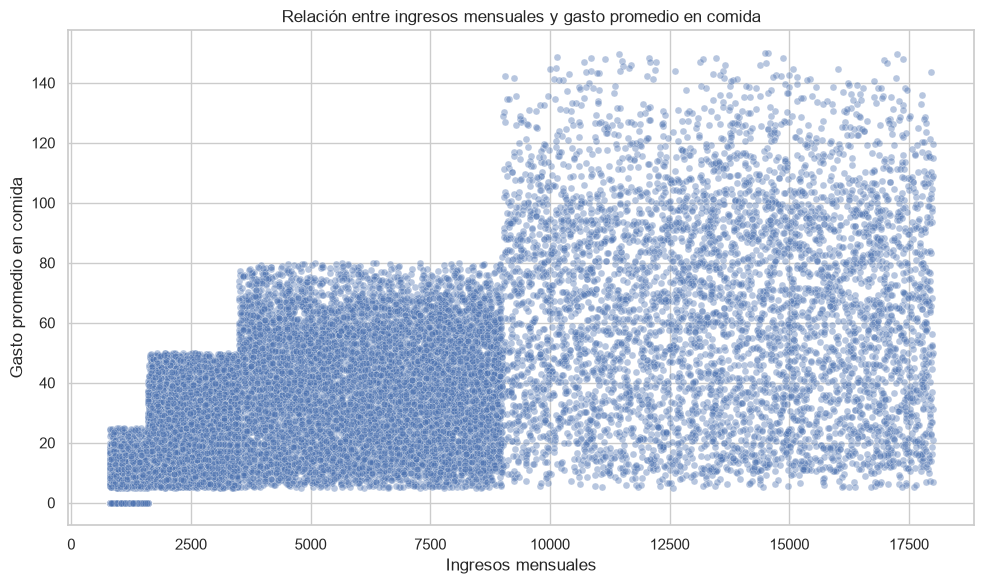

In [39]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_gasto_ingresos,
    x="ingresos_mensuales",
    y="promedio_gasto_comida",
    alpha=0.4,
    s=25
)

plt.title("Relación entre ingresos mensuales y gasto promedio en comida")
plt.xlabel("Ingresos mensuales")
plt.ylabel("Gasto promedio en comida")

plt.tight_layout()
plt.show()

#Se calculó el coeficiente de correlación de Pearson para medir la relación lineal entre los ingresos mensuales y el gasto promedio en comida.

In [40]:
correlacion = df_gasto_ingresos[
    "ingresos_mensuales"
].corr(
    df_gasto_ingresos["promedio_gasto_comida"]
)

correlacion

np.float64(0.6366924784780996)

#Se contabilizaron las preferencias alimenticias de los clientes, incluyendo los registros sin información, para identificar las categorías de mayor participación.

In [41]:
df["preferencias_alimenticias"].value_counts(dropna=False)

preferencias_alimenticias
Carnes         7916
Vegetariano    6580
Mariscos       5212
Vegano         3267
Pescado        2983
Otro           2639
NaN            1403
Name: count, dtype: int64

#Se utilizó una tabla cruzada (pd.crosstab) para comparar la distribución de preferencias alimenticias entre las diez ciudades.

In [42]:
preferencias_ciudad = pd.crosstab(
    df["ciudad_residencia"],
    df["preferencias_alimenticias"]
)

preferencias_ciudad

preferencias_alimenticias,Carnes,Mariscos,Otro,Pescado,Vegano,Vegetariano
ciudad_residencia,,,,,,
Boston,535,493,198,272,239,708
Chicago,1589,696,591,546,571,1123
Dallas,822,366,249,239,258,539
Denver,632,468,172,249,258,626
Houston,716,333,238,229,197,411
Miami,511,819,293,307,382,728
NYC,1513,799,396,436,588,837
Phoenix,416,209,154,200,155,301
San Diego,656,584,194,288,407,756


#Se reemplazaron los valores nulos de preferencias_alimenticias por la categoría «Sin información», para incluir todos los registros en la distribución por ciudad.

In [43]:
preferencias_ciudad = pd.crosstab(
    df["ciudad_residencia"],
    df["preferencias_alimenticias"].fillna("Sin información")
)

preferencias_ciudad

preferencias_alimenticias,Carnes,Mariscos,Otro,Pescado,Sin información,Vegano,Vegetariano
ciudad_residencia,,,,,,,
Boston,535,493,198,272,102,239,708
Chicago,1589,696,591,546,268,571,1123
Dallas,822,366,249,239,129,258,539
Denver,632,468,172,249,118,258,626
Houston,716,333,238,229,88,197,411
Miami,511,819,293,307,146,382,728
NYC,1513,799,396,436,200,588,837
Phoenix,416,209,154,200,76,155,301
San Diego,656,584,194,288,190,407,756


#Se calcularon los porcentajes de participación de cada preferencia alimenticia por ciudad y se representaron mediante un gráfico de barras apiladas al 100 %, facilitando la comparación de los hábitos alimenticios entre ciudades.

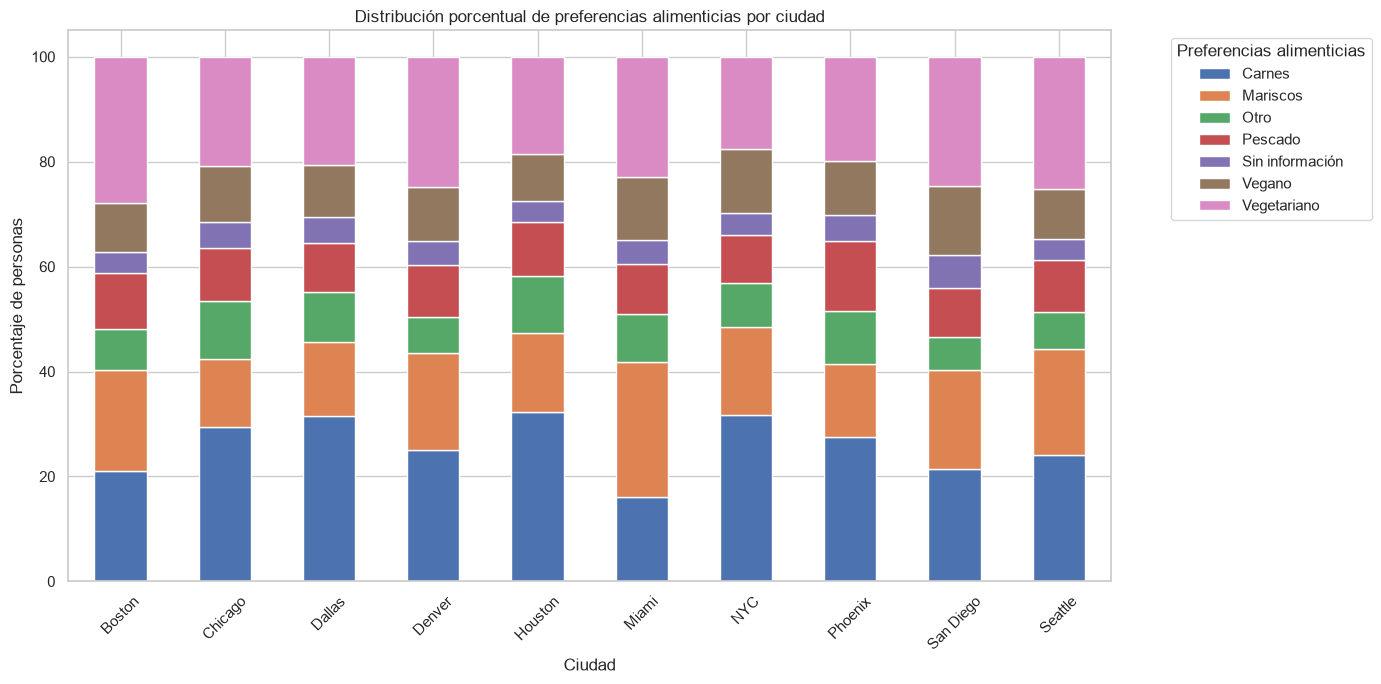

In [44]:
preferencias_porcentaje = preferencias_ciudad.div(
    preferencias_ciudad.sum(axis=1),
    axis=0
) * 100

preferencias_porcentaje.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.title("Distribución porcentual de preferencias alimenticias por ciudad")
plt.xlabel("Ciudad")
plt.ylabel("Porcentaje de personas")
plt.xticks(rotation=45)
plt.legend(
    title="Preferencias alimenticias",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

#Se calculó el percentil 75 (quantile(0.75)) del gasto promedio en comida para establecer el umbral de clasificación de los clientes con mayor gasto.

In [45]:
df["promedio_gasto_comida"].quantile(0.75)

np.float64(44.4)

#Se creó un subconjunto de clientes cuyo gasto promedio en comida es igual o superior a 44,40, correspondiente al percentil 75, para analizar sus preferencias y características de consumo.

In [46]:
clientes_mayor_gasto = df[
    df["promedio_gasto_comida"] >= 44.4
].copy()

#Se verificó la dimensión del subconjunto creado, obteniendo 7.465 clientes y 17 variables, que representan aproximadamente el 25 % de los registros con gasto promedio más alto.

In [47]:
clientes_mayor_gasto.shape

(7465, 17)

#Se analizaron las preferencias alimenticias del segmento de clientes con mayor gasto para identificar sus principales intereses gastronómicos.

In [48]:
clientes_mayor_gasto["preferencias_alimenticias"].value_counts(
    dropna=False
)

preferencias_alimenticias
Carnes         1881
Vegetariano    1697
Mariscos       1348
Vegano          840
Pescado         729
Otro            608
NaN             362
Name: count, dtype: int64

#Se calcularon las estadísticas descriptivas del gasto promedio del segmento seleccionado para conocer su comportamiento de consumo.

In [49]:
clientes_mayor_gasto["promedio_gasto_comida"].describe()

count    7465.000000
mean       69.883953
std        22.849328
min        44.400000
25%        52.070000
50%        63.150000
75%        80.790000
max       149.970000
Name: promedio_gasto_comida, dtype: float64

#Se contabilizaron los clientes según su condición de membresía premium para identificar la participación de este servicio en la base de datos.

In [50]:
df["membresia_premium"].value_counts(dropna=False)

membresia_premium
No    17155
Sí    12845
Name: count, dtype: int64

#Se utilizó pd.crosstab() para relacionar la ciudad de residencia con la condición de membresía premium, identificando la cantidad de clientes afiliados y no afiliados en cada ciudad.

In [51]:
membresias_ciudad = pd.crosstab(
    df["ciudad_residencia"],
    df["membresia_premium"]
)

membresias_ciudad

membresia_premium,No,Sí
ciudad_residencia,,
Boston,1408,1139
Chicago,3169,2215
Dallas,1610,992
Denver,1455,1068
Houston,1404,808
Miami,1492,1694
NYC,2994,1775
Phoenix,882,629
San Diego,1573,1502


#Se calculó el total de clientes y el porcentaje de afiliación premium en cada ciudad. Los resultados se ordenaron de mayor a menor para identificar los mercados con mayor participación de clientes afiliados.

In [52]:
membresias_ciudad["total_clientes"] = (
    membresias_ciudad["Sí"] + membresias_ciudad["No"]
)

membresias_ciudad["porcentaje_premium"] = (
    membresias_ciudad["Sí"] /
    membresias_ciudad["total_clientes"]
) * 100

membresias_ciudad.sort_values(
    by="porcentaje_premium",
    ascending=False
)

membresia_premium,No,Sí,total_clientes,porcentaje_premium
ciudad_residencia,,,,
Miami,1492,1694,3186,53.170119
San Diego,1573,1502,3075,48.845528
Seattle,1168,1023,2191,46.691009
Boston,1408,1139,2547,44.719278
Denver,1455,1068,2523,42.330559
Phoenix,882,629,1511,41.628061
Chicago,3169,2215,5384,41.140416
Dallas,1610,992,2602,38.124520
NYC,2994,1775,4769,37.219543


#Se elaboró un gráfico de barras para comparar el porcentaje de clientes con membresía premium entre las diez ciudades e identificar aquellas con mayor nivel de afiliación

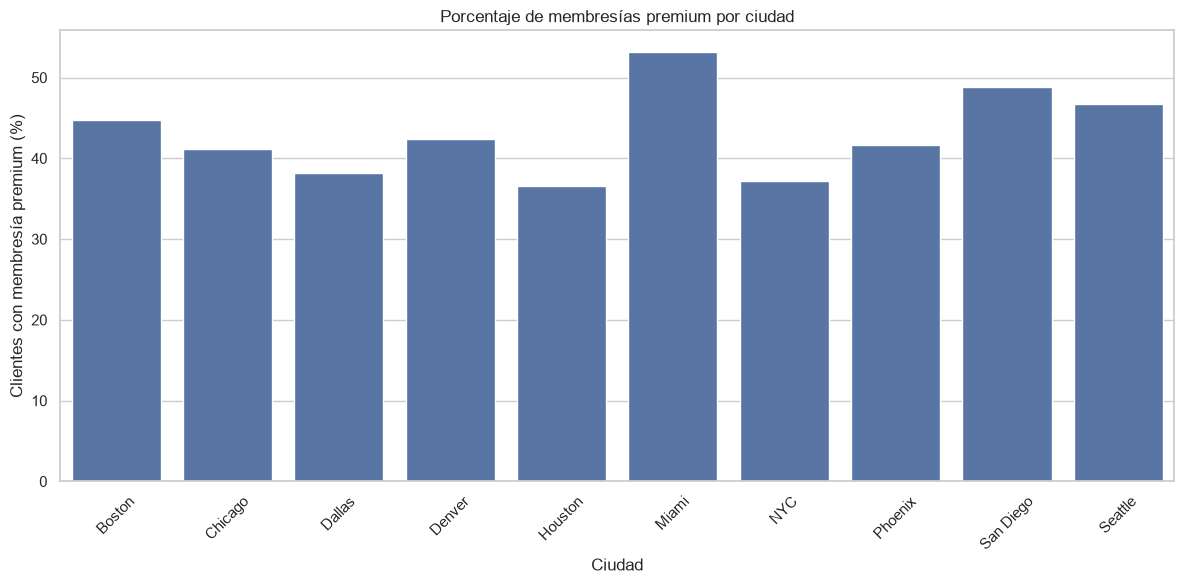

In [53]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=membresias_ciudad.index,
    y=membresias_ciudad["porcentaje_premium"]
)

plt.title("Porcentaje de membresías premium por ciudad")
plt.xlabel("Ciudad")
plt.ylabel("Clientes con membresía premium (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#Se agruparon los clientes según su consumo de licor y se calcularon estadísticas descriptivas de edad para comparar ambos grupos.

In [54]:
df.groupby("consume_licor")["edad"].describe()

,count,mean,std,min,25%,50%,75%,max
consume_licor,,,,,,,,
No,11467.0,54.651522,24.280990,-5.0,40.0,52.0,70.0,300.0
Sí,18432.0,46.562771,23.022716,-5.0,28.0,46.0,62.0,300.0


#Se identificaron registros con edades inferiores a 0 o superiores a 100 años, agrupados según el consumo de licor.

In [55]:
df[
    (df["edad"] < 0) |
    (df["edad"] > 100)
].groupby("consume_licor")["edad"].count()

consume_licor
No    104
Sí    103
Name: edad, dtype: int64

#Se creó el DataFrame df_edad_licor, excluyendo edades inferiores a 0 o superiores a 100 y registros sin información sobre consumo de licor, para realizar una comparación más consistente

In [56]:
df_edad_licor = df[
    (df["edad"] >= 0) &
    (df["edad"] <= 100) &
    (df["consume_licor"].notna())
].copy()

#Después de aplicar los filtros, se conservaron 29.692 registros y 17 variables, que serán utilizados para analizar la distribución de edades según el consumo de licor

In [57]:
df_edad_licor.shape

(29692, 17)

#Se elaboró un diagrama de cajas (boxplot) para comparar la distribución de edades entre los clientes que consumen licor y quienes no lo hacen, identificando diferencias en sus medianas y dispersión

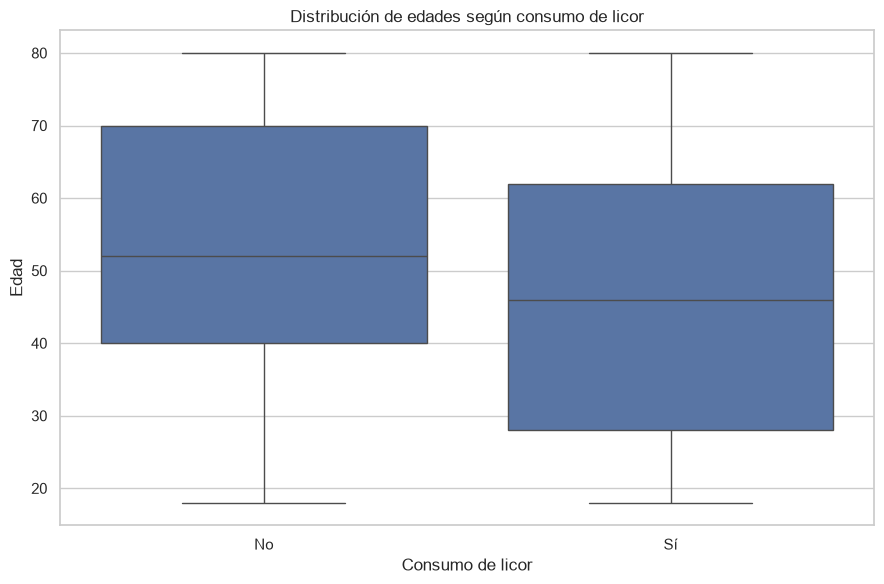

In [58]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_edad_licor,
    x="consume_licor",
    y="edad"
)

plt.title("Distribución de edades según consumo de licor")
plt.xlabel("Consumo de licor")
plt.ylabel("Edad")

plt.tight_layout()
plt.show()

#Se construyó una tabla comparativa con las preferencias alimenticias de los clientes del Avance 1 y las categorías gastronómicas identificadas mediante Yelp API en el Avance 2.
El objetivo es relacionar la demanda de los clientes con la oferta de restaurantes para identificar posibles oportunidades de mercado.

In [59]:
resumen_oportunidades = pd.DataFrame({
    "preferencia": [
        "Vegetariano",
        "Vegano",
        "Carnes",
        "Mariscos",
        "Pescado"
    ],
    "clientes_boston": [708, 239, 535, 493, 272],
    "restaurantes_yelp": [1, 0, 24, 29, 41]
})

resumen_oportunidades

,preferencia,clientes_boston,restaurantes_yelp
0,Vegetariano,708,1
1,Vegano,239,0
2,Carnes,535,24
3,Mariscos,493,29
4,Pescado,272,41


#Se calcularon los porcentajes de participación utilizando como referencia los 2.547 clientes y los 200 restaurantes de Boston.
Esto permite comparar proporcionalmente las preferencias alimenticias de los clientes con las categorías gastronómicas identificadas en Yelp.

In [60]:
resumen_oportunidades["demanda_clientes_%"] = (
    resumen_oportunidades["clientes_boston"] / 2547
) * 100

resumen_oportunidades["oferta_restaurantes_%"] = (
    resumen_oportunidades["restaurantes_yelp"] / 200
) * 100

resumen_oportunidades.round(2)

,preferencia,clientes_boston,restaurantes_yelp,demanda_clientes_%,oferta_restaurantes_%
0,Vegetariano,708,1,27.80,0.5
1,Vegano,239,0,9.38,0.0
2,Carnes,535,24,21.01,12.0
3,Mariscos,493,29,19.36,14.5
4,Pescado,272,41,10.68,20.5


#Se elaboró un gráfico de barras agrupadas para comparar la participación porcentual de las preferencias alimenticias de los clientes frente a la oferta de restaurantes identificada en Boston

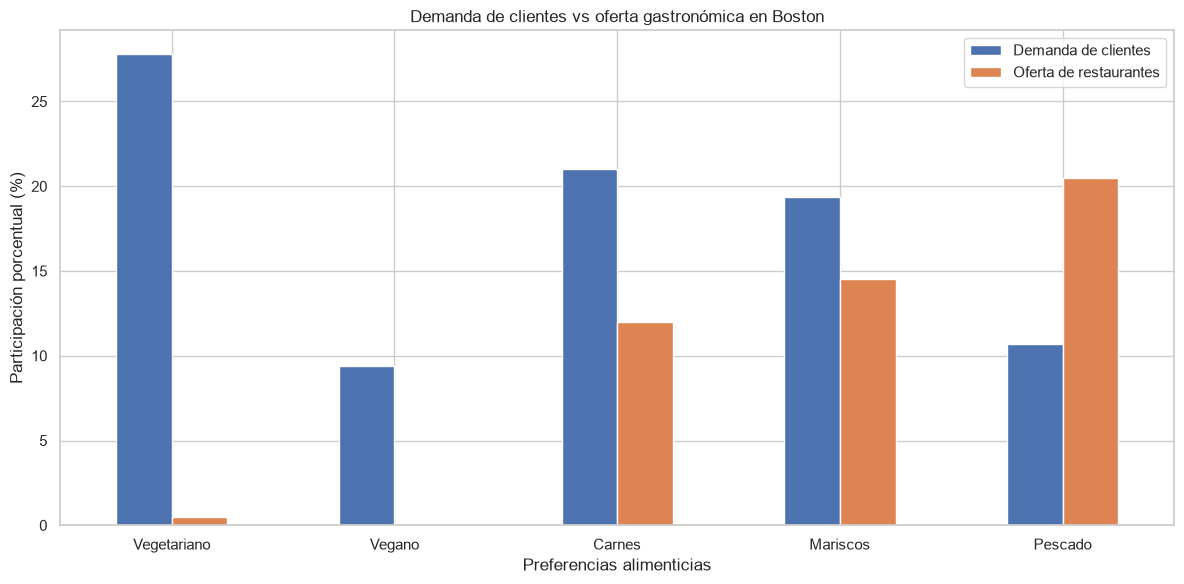

In [62]:
resumen_grafico = resumen_oportunidades.set_index("preferencia")[
    ["demanda_clientes_%", "oferta_restaurantes_%"]
]

resumen_grafico.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Demanda de clientes vs oferta gastronómica en Boston")
plt.xlabel("Preferencias alimenticias")
plt.ylabel("Participación porcentual (%)")
plt.xticks(rotation=0)
plt.legend(["Demanda de clientes", "Oferta de restaurantes"])
plt.tight_layout()
plt.show()